# Chapter 5: Evaluation

## 5.4 Visual Comparison and Analysis

Five test images were selected for visual comparison. They contain different types of edges, textures, and smooth regions. This allows the four denoising methods to be examined on different image content.

In [71]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoising_config import FLAT_FRACTION, METHOD_ORDER, denoise_mapped
from src.noise import add_gaussian_noise
from src.noise_level_estimators import edge_aware_laplacian_noise_estimate
from src.utils import load_grayscale_image

In [72]:
# Test settings
noise_levels = list(range(2, 16))
seed = 42
num_test_images = 100

test_dir = project_dir / "data" / "test"
result_dir = project_dir / "results" / "Chapter5_VisualComparison"
result_dir.mkdir(parents=True, exist_ok=True)

# Load the same test set used in Chapter 5
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(test_dir.rglob(pattern))

image_files = sorted(set(image_files))
if len(image_files) != num_test_images:
    raise FileNotFoundError(
        f"Expected {num_test_images} test images, but found {len(image_files)} in {test_dir}"
    )

test_images = [
    (image_file.stem, load_grayscale_image(image_file))
    for image_file in image_files
]

print("Number of test images:", len(test_images))

Number of test images: 100


### Selected test images

The five images cover different visual characteristics

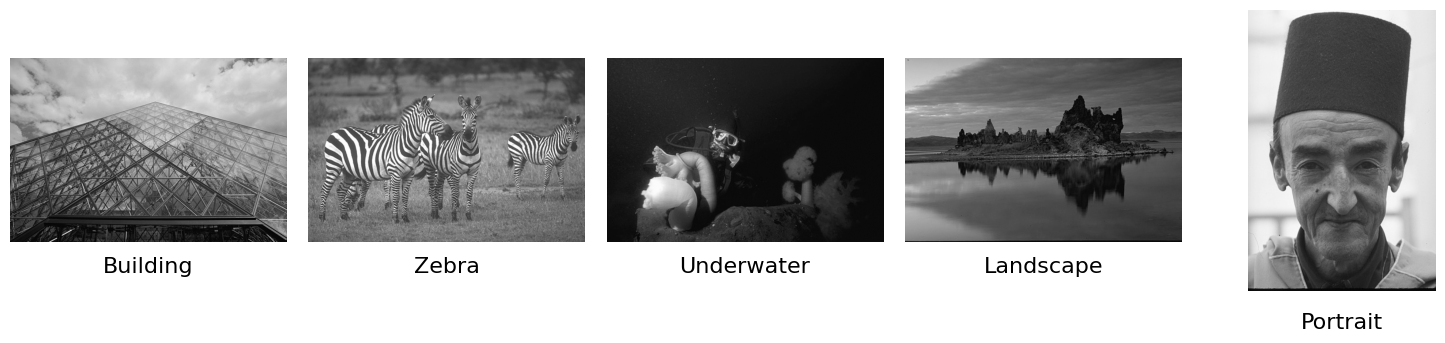

In [115]:
# Select the five images used for visual comparison
selected_specs = [
    ("045", "Building"),
    ("052", "Zebra"),
    ("081", "Underwater"),
    ("018", "Landscape"),
    ("035", "Portrait")
]

test_lookup = {
    image_name: (image_index, clean_image)
    for image_index, (image_name, clean_image) in enumerate(test_images)
}

selected_images = []
for image_name, label in selected_specs:
    if image_name not in test_lookup:
        raise FileNotFoundError(f"{image_name}.jpg was not found in the test set")

    image_index, clean_image = test_lookup[image_name]
    selected_images.append({
        "image_name": image_name,
        "label": label,
        "image_index": image_index,
        "clean_image": clean_image
    })

# Show the five clean images
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))

for ax, item in zip(axes, selected_images):
    ax.imshow(item["clean_image"], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
    ax.text(
        0.5, -0.08, f'{item["label"]}',
        transform=ax.transAxes, ha="center", va="top", fontsize=16
    )

fig.subplots_adjust(left=0.01, right=0.99, top=0.98, bottom=0.20, wspace=0.08)
fig.savefig(result_dir / "selected_test_images.png", dpi=300, bbox_inches="tight")
plt.show()

In [101]:
# Use the same noise cases as the quantitative evaluation
def make_case_seed(image_index, noise_percent):
    noise_index = noise_levels.index(noise_percent)
    return seed + noise_index * num_test_images + image_index


def create_visual_rows(noise_percent):
    rows = []

    for item in selected_images:
        clean_image = item["clean_image"]
        image_index = item["image_index"]

        noisy_image = add_gaussian_noise(
            clean_image, sigma=noise_percent / 100,
            seed=make_case_seed(image_index, noise_percent)
        ).astype(np.float32)

        estimated_percent = 100 * float(
            edge_aware_laplacian_noise_estimate(
                noisy_image, flat_fraction=FLAT_FRACTION
            )
        )

        denoised = {}
        for method in METHOD_ORDER:
            denoised[method] = denoise_mapped(
                noisy_image, method, estimated_percent
            )

        rows.append({
            "label": item["label"],
            "image_name": item["image_name"],
            "clean": clean_image,
            "noisy": noisy_image,
            "denoised": denoised
        })

    return rows


def plot_visual_comparison(noise_percent):
    rows = create_visual_rows(noise_percent)
    column_titles = ["Clean", f"Noisy ({noise_percent}%)","AD", "TV", "BF", "NLM"]

    # Use a separate column for row labels
    fig, axes = plt.subplots(
        5, 7, figsize=(15, 9.5),
        gridspec_kw={"width_ratios": [0.2, 1, 1, 1, 1, 1, 1]}
    )

    for row_index, row in enumerate(rows):
        # Row label
        axes[row_index, 0].axis("off")
        axes[row_index, 0].text(
            0.7, 0.5, row["label"],
            ha="center", va="center",
            fontsize=15, rotation=90
        )
        images = [
            row["clean"], row["noisy"],
            row["denoised"]["AD"], row["denoised"]["TV"],
            row["denoised"]["BF"], row["denoised"]["NLM"]
        ]

        for column_index, image in enumerate(images):
            ax = axes[row_index, column_index + 1]
            ax.imshow(image, cmap="gray", vmin=0, vmax=1)
            ax.axis("off")

            if row_index == 0:
                ax.set_title(column_titles[column_index], fontsize=15, pad=8)

    fig.subplots_adjust(
        left=0.03, right=0.99, top=0.93, bottom=0.02,
        wspace=0.04, hspace=0.02
    )

    fig.savefig(
        result_dir / f"visual_comparison_{noise_percent}_percent.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()

### 5.4.1 Low Noise: 4% Visual Comparison

At 4% noise, image content remains relatively clear. The comparison focuses on noise removal and the preservation of fine details.

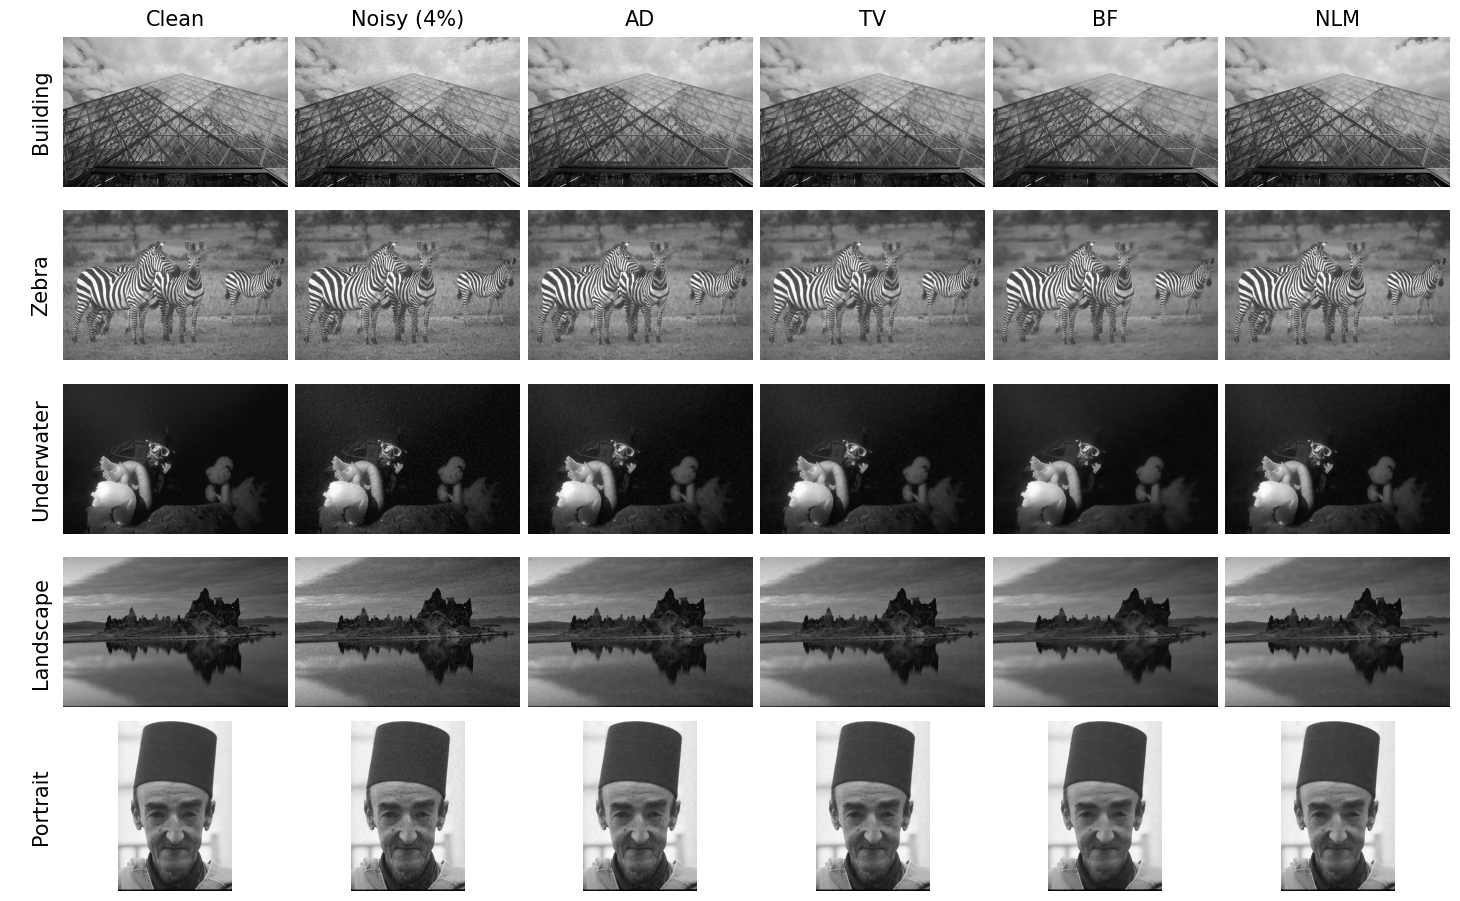

In [102]:
# Low-noise comparison
plot_visual_comparison(4)

### 5.4.2 Medium Noise: 8% Visual Comparison

At 8% noise, degradation becomes more visible. The comparison examines the balance between noise removal and the preservation of edges and textures.

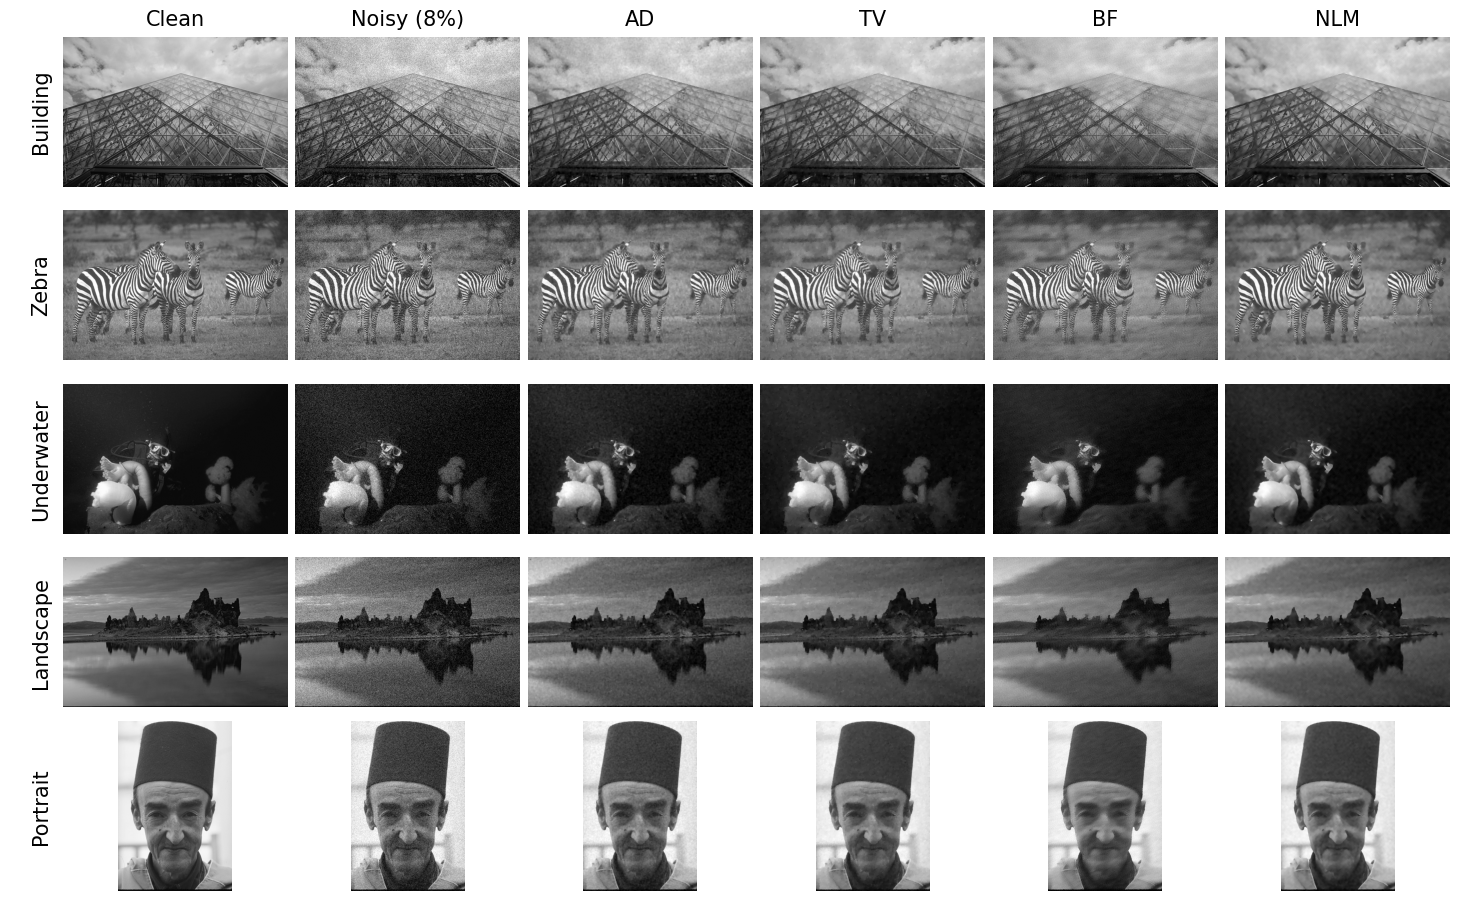

In [113]:
# Medium-noise comparison
plot_visual_comparison(8)

### 5.4.3 High Noise: 15% Visual Comparison

At 15% noise, more detail is affected. The comparison focuses on residual noise, over-smoothing, and the loss of important structures.

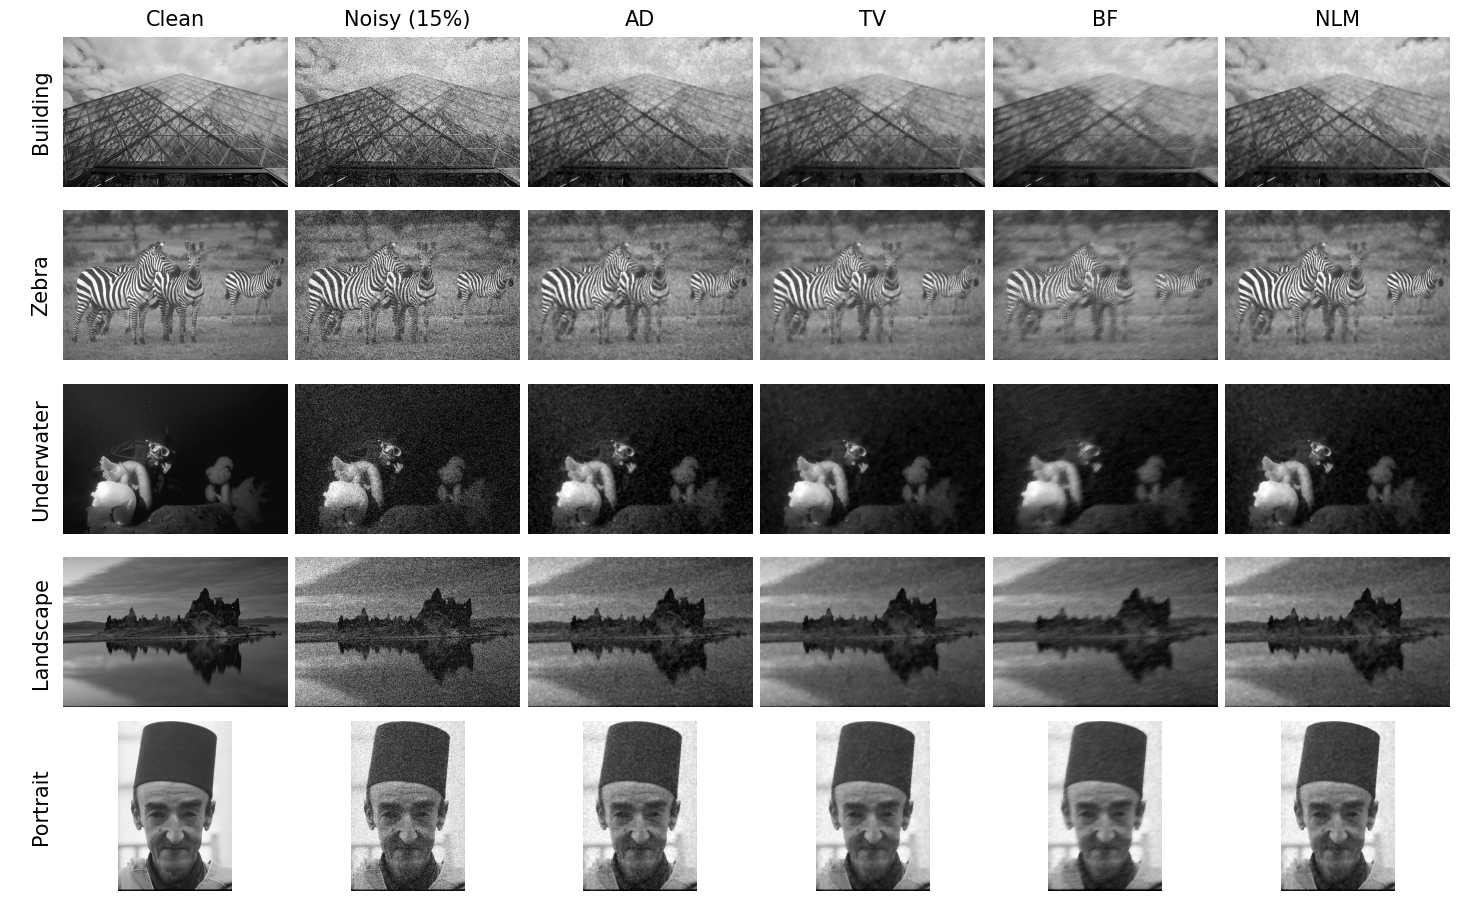

In [114]:
# High-noise comparison
plot_visual_comparison(15)